In [3]:
import pandas as pd
import glob
import numpy as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
paths = glob.glob("../../raw_data/HALO_outputs/*")
for n in range(0,len(paths)):
    df = pd.read_csv(paths[n])
    df['sample_id'] = 'Br'+paths[n].split('Br')[1].split('_DLPFC')[0]
    if n == 0:
        all_df = df
    else:
        all_df = pd.concat([all_df, df], axis = 0)

In [17]:
custom_palette = {
    'Br2934': '#4B8D86',  
    'Br5347': '#C3B3A1',  
    'Br5785': '#C3B3A1',  
    'Br5766': '#4B8D86',  
    'Br5394': '#4B8D86',  
    'Br9413': '#C3B3A1',  
}

custom_order = ['Br5347', 'Br5785', 'Br9413', 'Br2934', 'Br5766', 'Br5394']

## PD oligodendrocytes have lower MBP intensity overall

<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

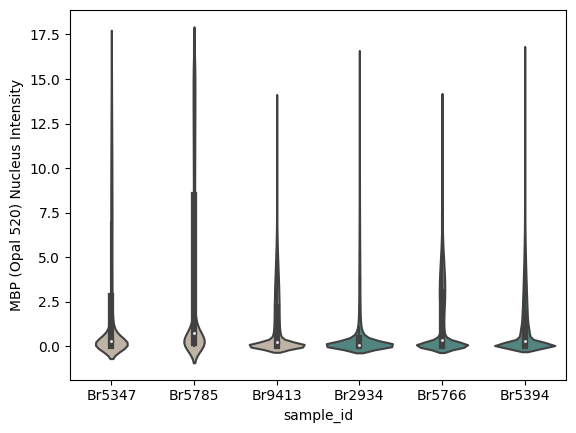

In [19]:
# Overall MBP nucleus intensity signal

sns.violinplot(x = all_df['sample_id'], y = all_df['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

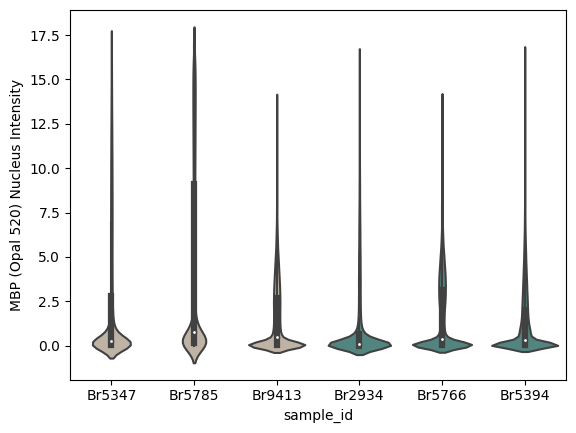

In [20]:
# MBP intensity for cells only

iscell = all_df[all_df['DAPI (DAPI) Positive']==1]
sns.violinplot(x = iscell['sample_id'], y = iscell['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

(162416, 38)


<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

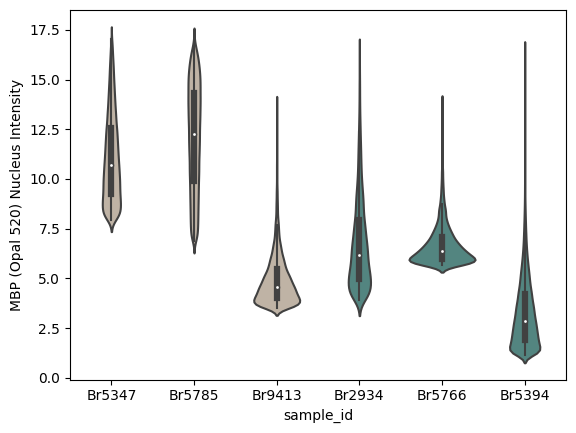

In [21]:
# MBP intensity only for MBP positive cells

iscell = all_df[(all_df['MBP (Opal 520) Positive']==1) & (all_df['DAPI (DAPI) Positive']==1)]
print(np.shape(iscell))
sns.violinplot(x = iscell['sample_id'], y = iscell['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

(168506, 38)


<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

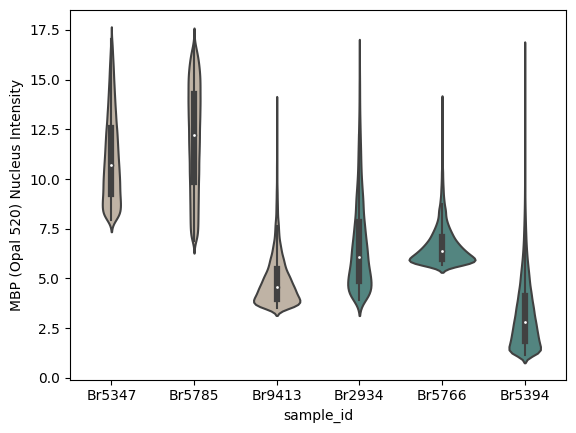

In [22]:
# MBP intensity only for MBP positive dots

iscell = all_df[all_df['MBP (Opal 520) Positive']==1]
print(np.shape(iscell))
sns.violinplot(x = iscell['sample_id'], y = iscell['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

## PD has less % of oligodendrocytes overall

In [36]:
paths = glob.glob("../../raw_data/HALO_outputs/*")
for n in range(0,len(paths)):
    sample_info = []
    df = pd.read_csv(paths[n])
    
    countsMBP = np.shape(df[(df['MBP (Opal 520) Positive']==1) & (df['DAPI (DAPI) Positive']==1)])[0]
    sample_info.append(countsMBP)
    
    countsDAPI = np.shape(df[(df['DAPI (DAPI) Positive']==1)])[0]
    sample_info.append(countsDAPI)
    
    ratio = (countsMBP/countsDAPI)*100
    sample_info.append(ratio)
    
    if n == 0:
        all_results = pd.DataFrame(sample_info, columns = ['Br'+paths[n].split('Br')[1].split('_DLPFC')[0]], index = ['counts MBP', 'counts DAPI', '% MBP+ cells'])
    else:
        results = pd.DataFrame(sample_info, columns = ['Br'+paths[n].split('Br')[1].split('_DLPFC')[0]], index = ['counts MBP', 'counts DAPI', '% MBP+ cells'])
        all_results = pd.concat([all_results, results], axis =1)
all_results = all_results.T

In [39]:
map_sample_type = {
    'Br2934': 'PD',  
    'Br5347': 'Control',  
    'Br5785': 'Control',  
    'Br5766': 'PD',  
    'Br5394': 'PD',  
    'Br9413': 'Control',  
}

all_results['group'] = all_results.index.map(map_sample_type)

<AxesSubplot:xlabel='group', ylabel='% MBP+ cells'>

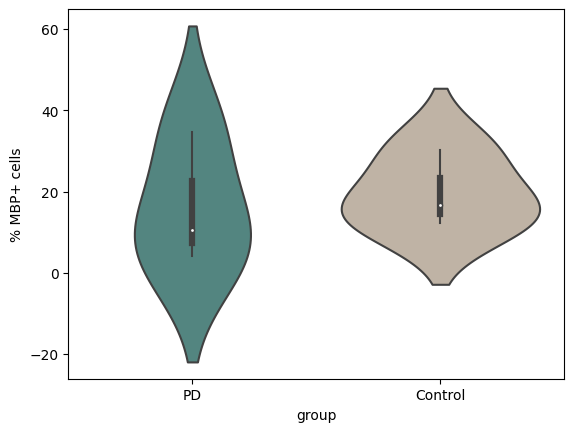

In [55]:
custom_palette = {
    'PD': '#4B8D86',  
    'Control': '#C3B3A1',  
}

sns.violinplot(x = all_results['group'], y = all_results['% MBP+ cells'], palette = custom_palette)
#sns.swarmplot(x = all_results['group'], y = all_results['% MBP+ cells'], color = 'black')